# Notebook 9 – Data Transformation

## 1. Why transform data?
Transformations can reduce skew, stabilize variance, or make patterns easier for some models to learn. They change the feature scale and interpretation; they are not automatically beneficial.

3.5432482519590107


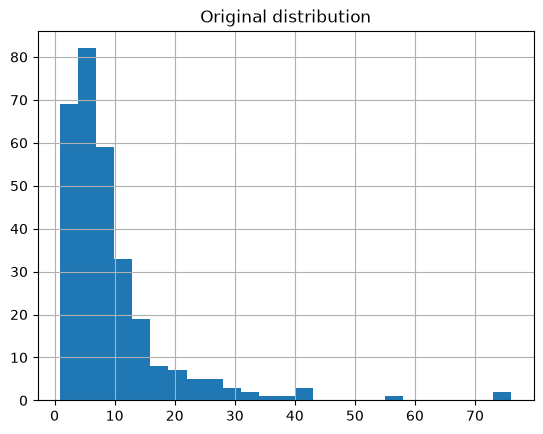

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import PowerTransformer

rng = np.random.default_rng(42)
values = pd.Series(rng.lognormal(mean=2.0, sigma=0.8, size=300), name="right_skewed")
print(values.skew())
values.hist(bins=25)
plt.title("Original distribution")
plt.show()

## 2. Log and square-root transformations
`log1p(x)` computes log(1+x) and supports zero values but not values below -1. Square-root transformation is often used for nonnegative right-skewed counts. Negative values require a different approach or careful domain-specific handling.

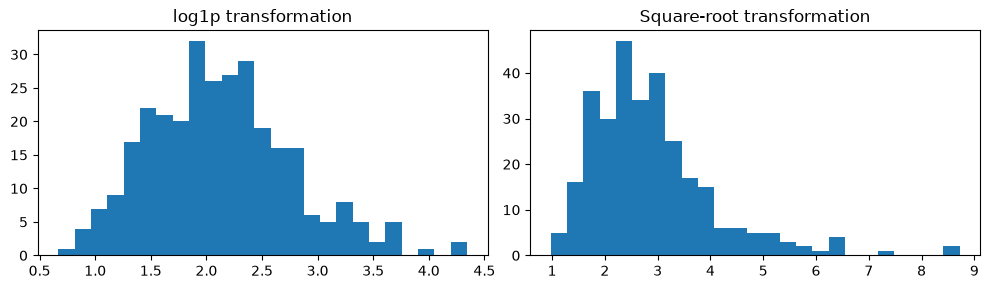

Original skew: 3.543
Log skew: 0.567
Square-root skew: 1.669


In [2]:
log_values = np.log1p(values)
sqrt_values = np.sqrt(values)
fig, axes = plt.subplots(1, 2, figsize=(10, 3))
axes[0].hist(log_values, bins=25)
axes[0].set_title("log1p transformation")
axes[1].hist(sqrt_values, bins=25)
axes[1].set_title("Square-root transformation")
plt.tight_layout()
plt.show()
print("Original skew:", round(values.skew(), 3))
print("Log skew:", round(log_values.skew(), 3))
print("Square-root skew:", round(sqrt_values.skew(), 3))

## 3. Power, Box-Cox, and Yeo-Johnson transformations
Power transformations can reduce skew. Box-Cox requires strictly positive input. Yeo-Johnson supports positive, zero, and negative values. The transformation parameters are learned from data and should be fitted on training data only.

In [3]:
positive = values.to_numpy().reshape(-1, 1)
boxcox = PowerTransformer(method="box-cox")
yeojohnson = PowerTransformer(method="yeo-johnson")
boxcox_result = boxcox.fit_transform(positive).ravel()
yeo_result = yeojohnson.fit_transform(positive).ravel()
print("Box-Cox skew:", round(pd.Series(boxcox_result).skew(), 3))
print("Yeo-Johnson skew:", round(pd.Series(yeo_result).skew(), 3))

Box-Cox skew: -0.002
Yeo-Johnson skew: 0.012


## 4. Normalization and standardization
Normalization may refer to row-wise vector normalization or scaling features to a fixed range; state which meaning you use. Standardization centers and scales each feature. These are not the same as distribution-shaping power transformations.

In [4]:
from sklearn.preprocessing import StandardScaler, MinMaxScaler, Normalizer
matrix = values.to_numpy().reshape(-1, 1)
print("Standardized first 5:", StandardScaler().fit_transform(matrix)[:5].ravel().round(2))
print("Min-max first 5:", MinMaxScaler().fit_transform(matrix)[:5].ravel().round(2))
print("Row-normalized first 5:", Normalizer().fit_transform(matrix)[:5].ravel().round(2))

Standardized first 5: [-0.02 -0.68  0.41  0.64 -0.86]
Min-max first 5: [0.11 0.03 0.17 0.2  0.01]
Row-normalized first 5: [1. 1. 1. 1. 1.]


**Output explanation:** The methods serve different purposes. Compare histograms and skew before/after, consider whether negatives/zeros are present, and evaluate the impact on the intended model.